# SmartIDS - Développement de Modèles (Data Mining)

Ce notebook suit rigoureusement la méthodologie **CRISP-DM** pour concevoir un modèle de détection d'intrusions réseau performant à partir du jeu de données **NSL-KDD**.

## Phase 1 : Business Understanding

### Contexte métier
Les intrusions réseau constituent une menace constante pour la sécurité des systèmes d'information. Les systèmes traditionnels basés sur des signatures échouent souvent face aux attaques de type *Zero-Day* ou aux variantes d'attaques connues.

### Objectif du projet
L'objectif de cette étude est d'utiliser le Data Mining pour construire un système intelligent capable d'identifier les anomalies réseau en classant les flux de connexions :
1. **En mode Binaire** : Normal vs. Attaque (Détection d'intrusion générale).
2. **En mode Multiclasse** : Normal, DoS, Probe, R2L, U2R (Identification de la famille d'attaque).

### Critères de réussite
- Un score Recall élevé pour minimiser les faux négatifs (attaques non détectées).
- Une précision acceptable pour éviter d'inonder les administrateurs de fausses alertes (faux positifs).
- Des modèles exportables (`.pkl`) pour une intégration en temps réel dans une application Flask.

## Phase 2 : Data Understanding

Dans cette phase, nous importons les données, explorons la structure globale (dimensions, types de données, valeurs manquantes) et réalisons des visualisations clés.

In [1]:
## 2.1 Importation des bibliothèques
# ==========================================================
# Importation des bibliothèques
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Configuration d'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [2]:
## 2.2 Chargement du jeu de données
# ==========================================================
# Définition des colonnes du dataset NSL-KDD
# ==========================================================
# Colonnes du dataset NSL-KDD
columns = [
'duration','protocol_type','service','flag','src_bytes','dst_bytes',
'land','wrong_fragment','urgent','hot','num_failed_logins',
'logged_in','num_compromised','root_shell','su_attempted',
'num_root','num_file_creations','num_shells','num_access_files',
'num_outbound_cmds','is_host_login','is_guest_login',
'count','srv_count','serror_rate','srv_serror_rate',
'rerror_rate','srv_rerror_rate','same_srv_rate','diff_srv_rate',
'srv_diff_host_rate','dst_host_count','dst_host_srv_count',
'dst_host_same_srv_rate','dst_host_diff_srv_rate',
'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate',
'dst_host_serror_rate','dst_host_srv_serror_rate',
'dst_host_rerror_rate','dst_host_srv_rerror_rate',
'attack','difficulty'
]
# ==========================================================
# Chargement des datasets d'entraînement et de test
# ==========================================================

train_path = "../Dataset/KDDTrain+.txt"
test_path = "../Dataset/KDDTest+.txt"

train_df = pd.read_csv(train_path, names=columns)
test_df = pd.read_csv(test_path, names=columns)

print("Train Shape :", train_df.shape)
print("Test Shape  :", test_df.shape)

Train Shape : (125973, 43)
Test Shape  : (22544, 43)


In [3]:
## 2.3 Aperçu des données
# ==========================================================
# Aperçu des premières observations
# ==========================================================

display(train_df.head())

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [4]:
# ==========================================================
# Aperçu des dernières observations
# ==========================================================

display(train_df.tail())

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,difficulty
125968,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,184,25,1.0,1.0,0.0,0.0,0.14,0.06,0.0,255,25,0.10,0.06,0.00,0.0,1.00,1.0,0.00,0.0,neptune,20
125969,8,udp,private,SF,105,145,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.0,255,244,0.96,0.01,0.01,0.0,0.00,0.0,0.00,0.0,normal,21
125970,0,tcp,smtp,SF,2231,384,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0.0,0.0,0.0,0.0,1.00,0.00,0.0,255,30,0.12,0.06,0.00,0.0,0.72,0.0,0.01,0.0,normal,18
125971,0,tcp,klogin,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,144,8,1.0,1.0,0.0,0.0,0.06,0.05,0.0,255,8,0.03,0.05,0.00,0.0,1.00,1.0,0.00,0.0,neptune,20
125972,0,tcp,ftp_data,SF,151,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0.0,0.0,0.0,0.0,1.00,0.00,0.0,255,77,0.30,0.03,0.30,0.0,0.00,0.0,0.00,0.0,normal,21


In [5]:
## 2.4 Informations générales sur le dataset
# ==========================================================
# Informations générales
# ==========================================================

train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13  root_shell

In [6]:
# ==========================================================
# Dimensions du dataset
# ==========================================================

print(f"Nombre de lignes     : {train_df.shape[0]}")
print(f"Nombre de colonnes   : {train_df.shape[1]}")

Nombre de lignes     : 125973
Nombre de colonnes   : 43


In [7]:
# ==========================================================
# Types des variables
# ==========================================================

train_df.dtypes.value_counts()

int64      24
float64    15
str         4
Name: count, dtype: int64

In [8]:
## 2.5 Qualité des données
# ==========================================================
# Vérification des valeurs manquantes
# ==========================================================

missing = train_df.isnull().sum()

missing_df = pd.DataFrame({
    "Variable": train_df.columns,
    "Missing Values": missing.values,
    "Percentage (%)": (missing.values / len(train_df))*100
})

missing_df["Percentage (%)"] = missing_df["Percentage (%)"].round(2)

display(missing_df)

,Variable,Missing Values,Percentage (%)
0,duration,0,0.0
1,protocol_type,0,0.0
2,service,0,0.0
3,flag,0,0.0
4,src_bytes,0,0.0
5,dst_bytes,0,0.0
6,land,0,0.0
7,wrong_fragment,0,0.0
8,urgent,0,0.0
9,hot,0,0.0


In [9]:
print("Total Missing Values :", train_df.isnull().sum().sum())

Total Missing Values : 0


In [10]:
# ==========================================================
# Vérification des doublons
# ==========================================================

duplicates = train_df.duplicated().sum()

print("Duplicate Rows :", duplicates)

Duplicate Rows : 0


In [11]:
numeric_columns = train_df.select_dtypes(include=np.number)

print("Infinite Values :", np.isinf(numeric_columns).sum().sum())

Infinite Values : 0


In [12]:
memory = train_df.memory_usage(deep=True).sum()/1024**2

print(f"Dataset Memory : {memory:.2f} MB")

Dataset Memory : 43.38 MB


In [13]:
unique_df = pd.DataFrame({
    "Variable": train_df.columns,
    "Unique Values": train_df.nunique().values
})

display(unique_df)

,Variable,Unique Values
0,duration,2981
1,protocol_type,3
2,service,70
3,flag,11
4,src_bytes,3341
5,dst_bytes,9326
6,land,2
7,wrong_fragment,3
8,urgent,4
9,hot,28


In [14]:
## 2.6 Analyse de la variable cible
# Répartition des types d'attaques

train_df["attack"].value_counts()

attack
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

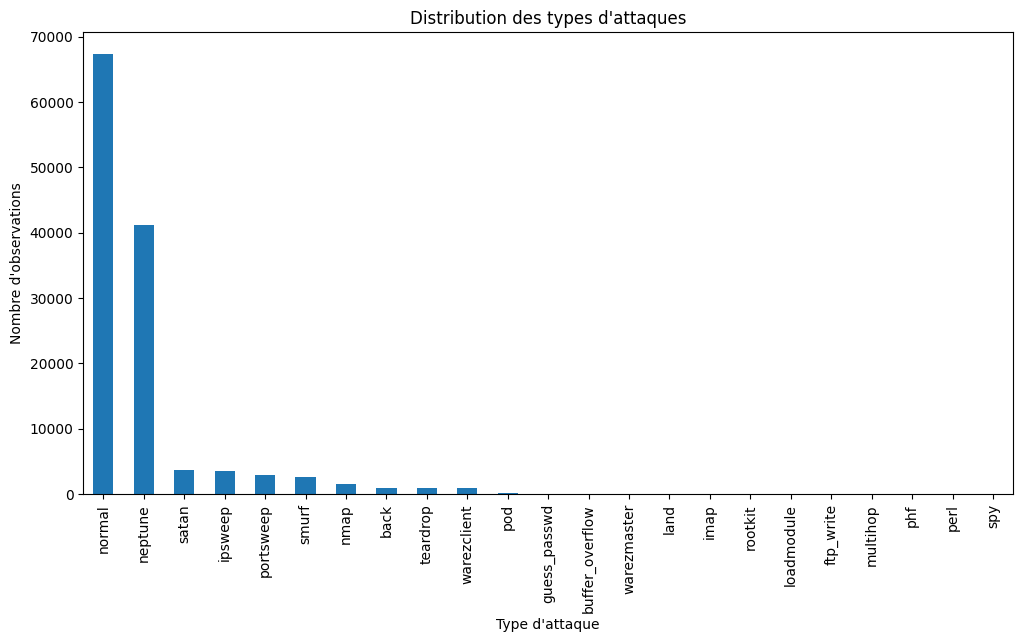

In [15]:
plt.figure(figsize=(12,6))

train_df["attack"].value_counts().plot(kind="bar")

plt.title("Distribution des types d'attaques")
plt.xlabel("Type d'attaque")
plt.ylabel("Nombre d'observations")

plt.xticks(rotation=90)

plt.show()

In [16]:
# Création de la classe binaire

train_df["binary_attack"] = train_df["attack"].apply(
    lambda x: "Normal" if x=="normal" else "Attack"
)
train_df["binary_attack"].value_counts()

binary_attack
Normal    67343
Attack    58630
Name: count, dtype: int64

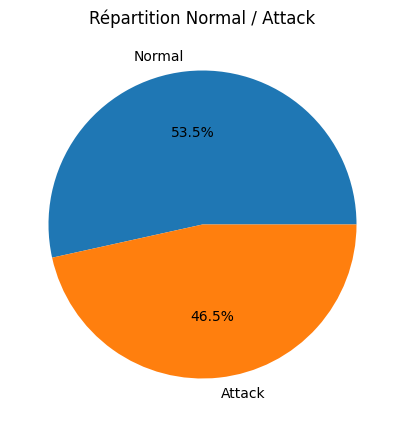

In [17]:
plt.figure(figsize=(5,5))

train_df["binary_attack"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")
plt.title("Répartition Normal / Attack")

plt.show()

In [18]:
dos = [
'back','land','neptune','pod','smurf',
'teardrop','mailbomb','apache2',
'processtable','udpstorm'
]

probe = [
'satan','ipsweep','nmap',
'portsweep','mscan','saint'
]

r2l = [
'guess_passwd','ftp_write','imap',
'phf','multihop','warezmaster',
'warezclient','spy','xlock',
'xsnoop','snmpguess','snmpgetattack',
'httptunnel','sendmail','named'
]

u2r = [
'buffer_overflow','loadmodule',
'rootkit','perl','sqlattack',
'xterm','ps'
]

In [19]:
def attack_category(attack):

    if attack == "normal":
        return "Normal"

    elif attack in dos:
        return "DoS"

    elif attack in probe:
        return "Probe"

    elif attack in r2l:
        return "R2L"

    elif attack in u2r:
        return "U2R"

    else:
        return "Unknown"

train_df["attack_class"] = train_df["attack"].apply(attack_category)
train_df["attack_class"].value_counts()

attack_class
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

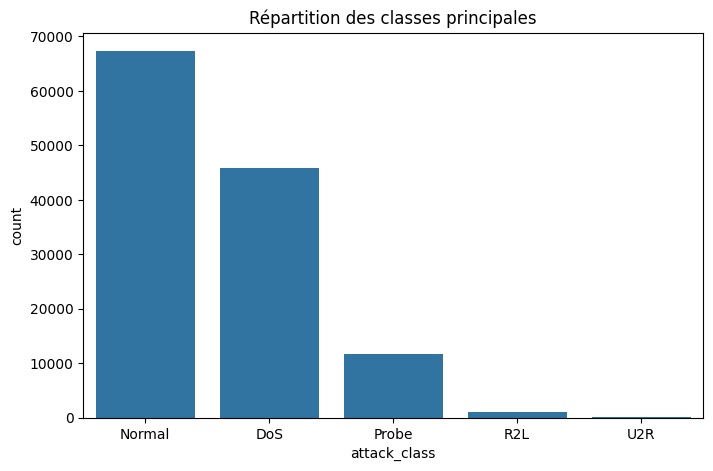

In [20]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=train_df,
    x="attack_class",
    order=train_df["attack_class"].value_counts().index
)

plt.title("Répartition des classes principales")

plt.show()

In [21]:
## 2.7 Analyse des variables catégorielles
# Répartition des protocoles

train_df["protocol_type"].value_counts()

protocol_type
tcp     102689
udp      14993
icmp      8291
Name: count, dtype: int64

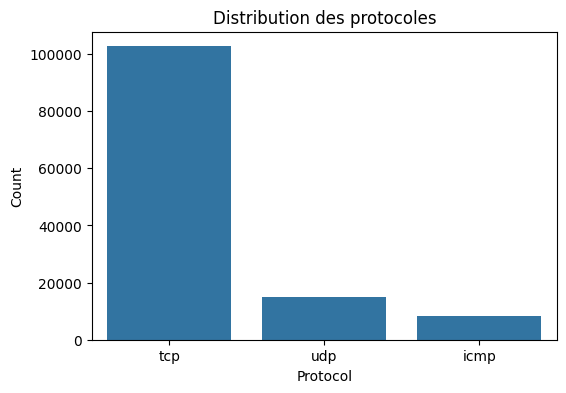

In [22]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=train_df,
    x="protocol_type",
    order=train_df["protocol_type"].value_counts().index
)

plt.title("Distribution des protocoles")
plt.xlabel("Protocol")
plt.ylabel("Count")

plt.show()

In [23]:
protocol_percent = train_df["protocol_type"].value_counts(normalize=True) * 100

protocol_percent.round(2)

protocol_type
tcp     81.52
udp     11.90
icmp     6.58
Name: proportion, dtype: float64

In [24]:
train_df["service"].value_counts().head(15)

service
http        40338
private     21853
domain_u     9043
smtp         7313
ftp_data     6860
eco_i        4586
other        4359
ecr_i        3077
telnet       2353
finger       1767
ftp          1754
auth          955
Z39_50        862
uucp          780
courier       734
Name: count, dtype: int64

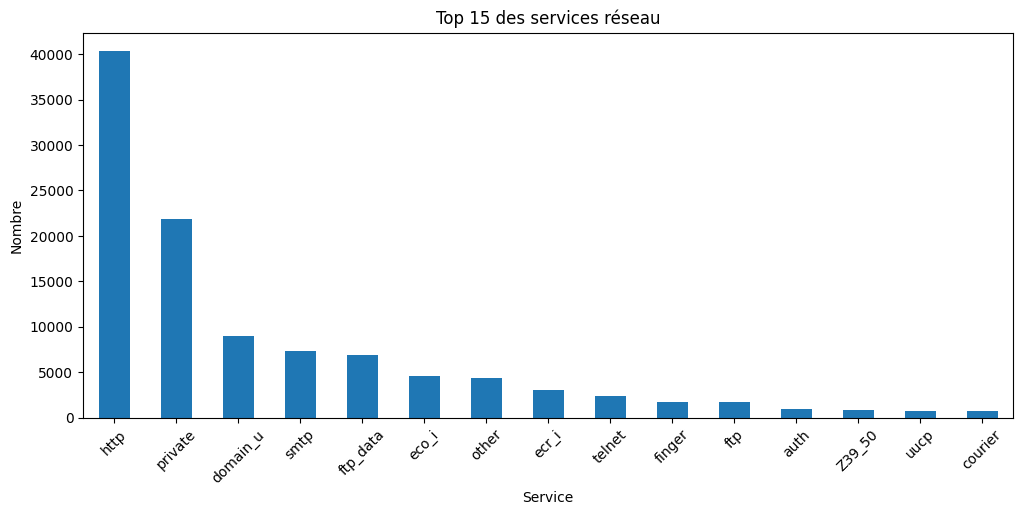

In [25]:
plt.figure(figsize=(12,5))

train_df["service"].value_counts().head(15).plot(kind="bar")

plt.title("Top 15 des services réseau")
plt.xlabel("Service")
plt.ylabel("Nombre")

plt.xticks(rotation=45)

plt.show()

In [26]:
train_df["flag"].value_counts()

flag
SF        74945
S0        34851
REJ       11233
RSTR       2421
RSTO       1562
S1          365
SH          271
S2          127
RSTOS0      103
S3           49
OTH          46
Name: count, dtype: int64

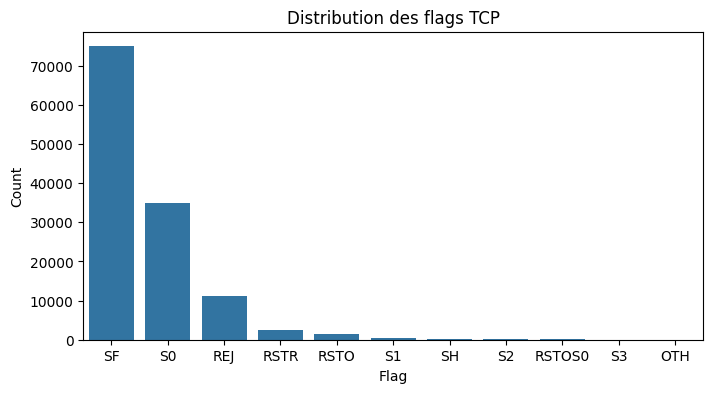

In [27]:
plt.figure(figsize=(8,4))

sns.countplot(
    data=train_df,
    x="flag",
    order=train_df["flag"].value_counts().index
)

plt.title("Distribution des flags TCP")
plt.xlabel("Flag")
plt.ylabel("Count")

plt.show()

In [28]:
summary = pd.DataFrame({
    "Variable": ["protocol_type","service","flag"],
    "Nombre de catégories":[
        train_df["protocol_type"].nunique(),
        train_df["service"].nunique(),
        train_df["flag"].nunique()
    ]
})

summary

,Variable,Nombre de catégories
0,protocol_type,3
1,service,70
2,flag,11


In [29]:
## 2.8 Corrélation entre les variables numériques
selected_columns = [
    "duration",
    "src_bytes",
    "dst_bytes",
    "count",
    "srv_count",
    "serror_rate",
    "same_srv_rate",
    "dst_host_count"
]
correlation = train_df[selected_columns].corr()

correlation

,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,same_srv_rate,dst_host_count
duration,1.000000,0.070737,0.034878,-0.079042,-0.039470,-0.069873,0.074681,0.050570
src_bytes,0.070737,1.000000,0.000204,-0.005152,-0.002792,-0.003228,0.003899,-0.005791
dst_bytes,0.034878,0.000204,1.000000,-0.003543,-0.001754,-0.003059,0.003788,0.002528
count,-0.079042,-0.005152,-0.003543,1.000000,0.471079,0.457556,-0.628024,0.468092
srv_count,-0.039470,-0.002792,-0.001754,0.471079,1.000000,-0.148260,0.190574,0.150407
serror_rate,-0.069873,-0.003228,-0.003059,0.457556,-0.148260,1.000000,-0.761888,0.395583
same_srv_rate,0.074681,0.003899,0.003788,-0.628024,0.190574,-0.761888,1.000000,-0.509781
dst_host_count,0.050570,-0.005791,0.002528,0.468092,0.150407,0.395583,-0.509781,1.000000


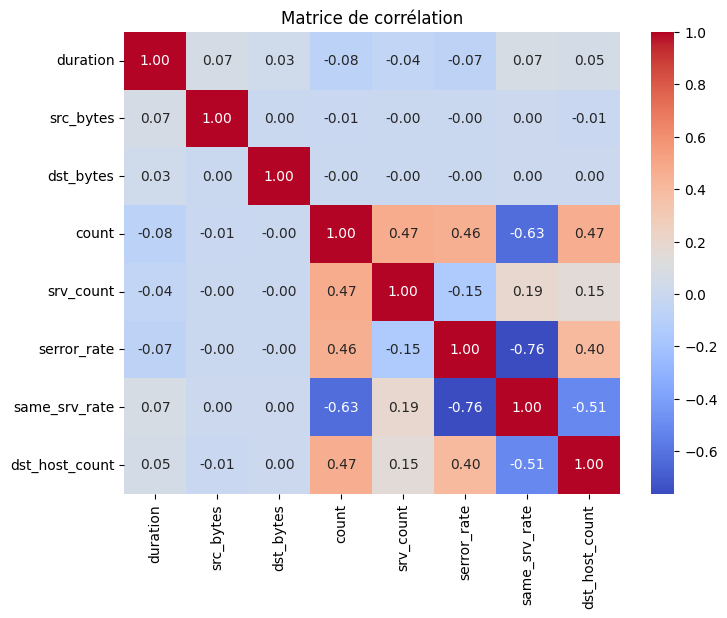

In [30]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matrice de corrélation")

plt.show()

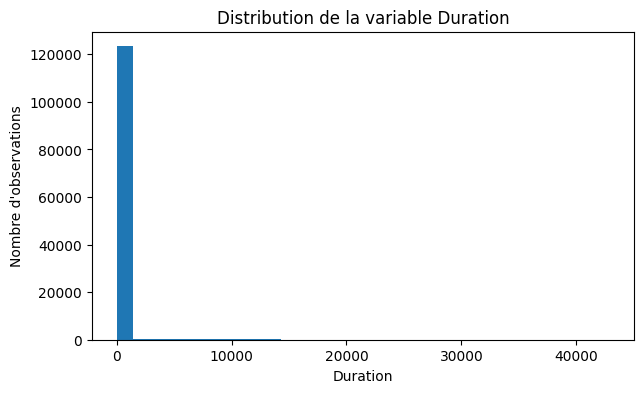

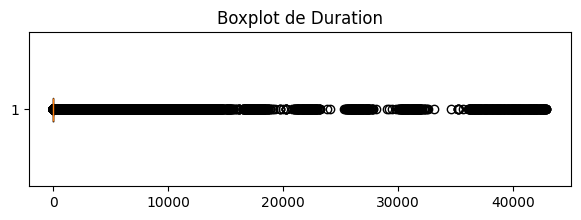

In [31]:
## 2.9 Analyse des variables numériques
plt.figure(figsize=(7,4))

plt.hist(train_df["duration"], bins=30)

plt.title("Distribution de la variable Duration")
plt.xlabel("Duration")
plt.ylabel("Nombre d'observations")

plt.show()

plt.figure(figsize=(7,2))

plt.boxplot(train_df["duration"], vert=False)

plt.title("Boxplot de Duration")

plt.show()

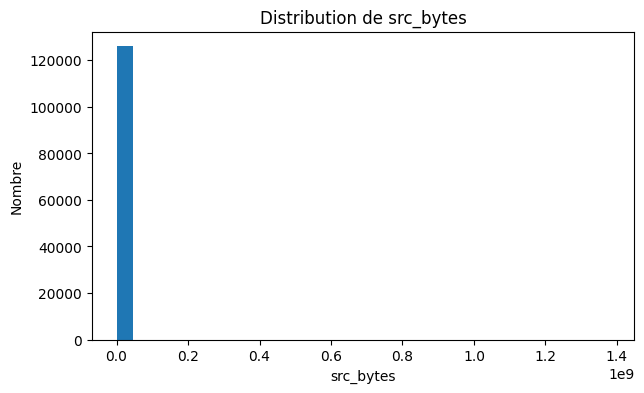

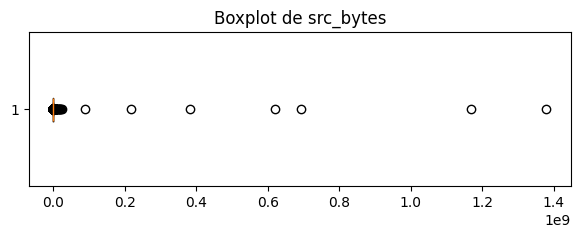

In [32]:
plt.figure(figsize=(7,4))

plt.hist(train_df["src_bytes"], bins=30)

plt.title("Distribution de src_bytes")
plt.xlabel("src_bytes")
plt.ylabel("Nombre")

plt.show()

plt.figure(figsize=(7,2))

plt.boxplot(train_df["src_bytes"], vert=False)

plt.title("Boxplot de src_bytes")

plt.show()

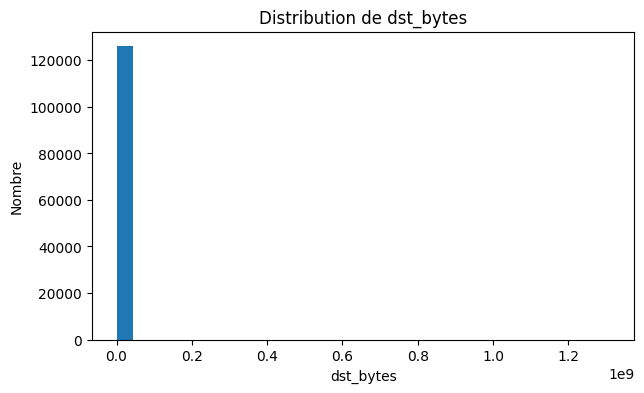

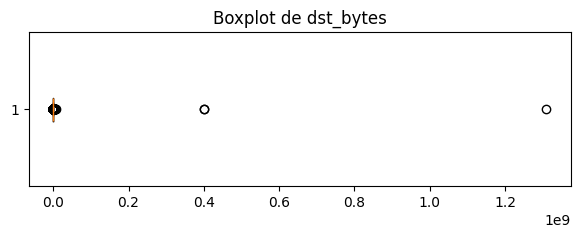

In [33]:
plt.figure(figsize=(7,4))

plt.hist(train_df["dst_bytes"], bins=30)

plt.title("Distribution de dst_bytes")
plt.xlabel("dst_bytes")
plt.ylabel("Nombre")

plt.show()

plt.figure(figsize=(7,2))

plt.boxplot(train_df["dst_bytes"], vert=False)

plt.title("Boxplot de dst_bytes")

plt.show()

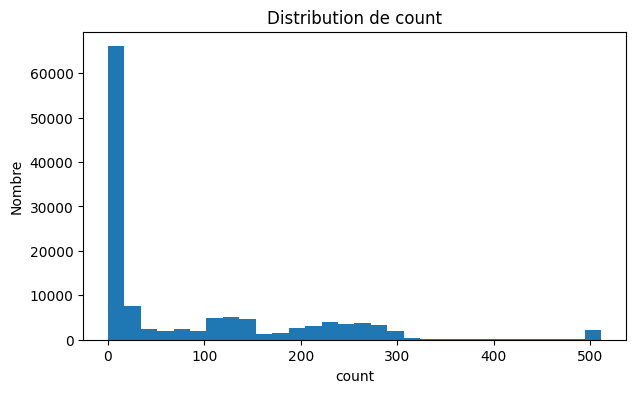

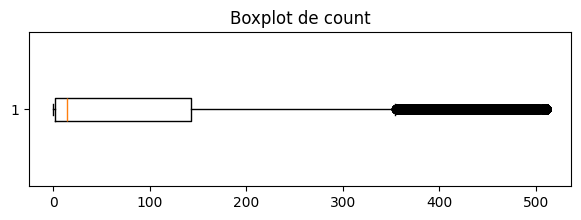

In [34]:
plt.figure(figsize=(7,4))

plt.hist(train_df["count"], bins=30)

plt.title("Distribution de count")
plt.xlabel("count")
plt.ylabel("Nombre")

plt.show()

plt.figure(figsize=(7,2))

plt.boxplot(train_df["count"], vert=False)

plt.title("Boxplot de count")

plt.show()

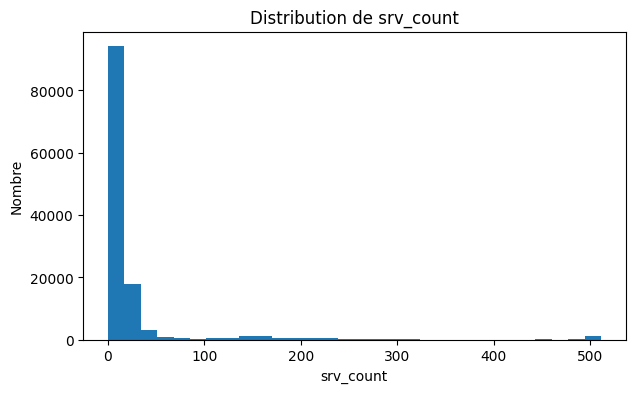

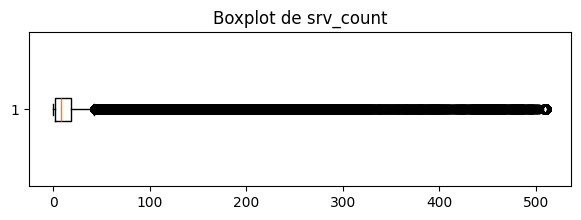

In [35]:
plt.figure(figsize=(7,4))

plt.hist(train_df["srv_count"], bins=30)

plt.title("Distribution de srv_count")
plt.xlabel("srv_count")
plt.ylabel("Nombre")

plt.show()


plt.figure(figsize=(7,2))

plt.boxplot(train_df["srv_count"], vert=False)

plt.title("Boxplot de srv_count")

plt.show()

In [36]:
## 2.10 Statistiques descriptives
train_df.describe()


display(train_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.00,0.00,0.00,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.00,44.00,276.00,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.00,0.00,516.00,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.00,0.00,0.00,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.00,0.00,0.00,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.00,0.00,0.00,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.00,0.00,0.00,7.479000e+03


## Phase 3 : Data Preparation

### Dans cette phase, les données sont préparées afin d'être exploitables par les algorithmes de Machine Learning.

### Les principales opérations sont :
## - Préparation des variables cibles
- Suppression des colonnes inutiles
- Encodage des variables catégorielles
- Normalisation des variables numériques
- Séparation des données
- Sauvegarde des objets de prétraitement

In [37]:
# ==========================================================
# 3.1 Création des variables cibles
# ==========================================================

# Classification binaire

test_df["binary_attack"] = test_df["attack"].apply(
    lambda x: "Normal" if x=="normal" else "Attack"
)

In [38]:
# Fonction de regroupement des attaques

def attack_category(attack):

    dos = [
        "back","land","neptune","pod","smurf",
        "teardrop","mailbomb","apache2",
        "processtable","udpstorm"
    ]

    probe = [
        "ipsweep","nmap","portsweep","satan",
        "mscan","saint"
    ]

    r2l = [
        "ftp_write","guess_passwd","imap","multihop",
        "phf","spy","warezclient","warezmaster",
        "sendmail","named","snmpgetattack",
        "snmpguess","xlock","xsnoop","worm"
    ]

    u2r = [
        "buffer_overflow","loadmodule",
        "perl","rootkit","httptunnel",
        "ps","sqlattack","xterm"
    ]

    if attack=="normal":
        return "Normal"

    elif attack in dos:
        return "DoS"

    elif attack in probe:
        return "Probe"

    elif attack in r2l:
        return "R2L"

    elif attack in u2r:
        return "U2R"

    else:
        return "Unknown"

In [39]:
train_df["attack_class"] = train_df["attack"].apply(attack_category)

test_df["attack_class"] = test_df["attack"].apply(attack_category)

In [40]:
print(train_df["attack_class"].value_counts())

print()

print(test_df["attack_class"].value_counts())

attack_class
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

attack_class
Normal    9711
DoS       7458
R2L       2754
Probe     2421
U2R        200
Name: count, dtype: int64


In [41]:
train_df.columns

Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
       'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
       'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
       'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate', 'attack', 'difficulty', 'binary_attack',
       'attack_class'],
      dtype='str')

In [42]:
test_df.columns

Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
       'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
       'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
       'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate', 'attack', 'difficulty', 'binary_attack',
       'attack_class'],
      dtype='str')

In [43]:
## 3.2 Création des jeux de données
# ==========================================================
# Création du dataset Binaire
# ==========================================================

binary_df = train_df.copy()

binary_df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,difficulty,binary_attack,attack_class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,Normal,Normal
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,Normal,Normal
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,Attack,DoS
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,Normal,Normal
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,Normal,Normal


In [44]:
# ==========================================================
# Création du dataset Multiclasse
# ==========================================================

multi_df = train_df.copy()

multi_df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,difficulty,binary_attack,attack_class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,Normal,Normal
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,Normal,Normal
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,Attack,DoS
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,Normal,Normal
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,Normal,Normal


In [45]:
# Variables explicatives

X_binary = binary_df.drop(
    columns=[
        "attack",
        "difficulty",
        "binary_attack",
        "attack_class"
    ]
)

# Variable cible

y_binary = binary_df["binary_attack"]

print(X_binary.shape)

print(y_binary.shape)

(125973, 41)
(125973,)


In [46]:
X_multi = multi_df.drop(
    columns=[
        "attack",
        "difficulty",
        "binary_attack",
        "attack_class"
    ]
)

y_multi = multi_df["attack_class"]

print(X_multi.shape)

print(y_multi.shape)

(125973, 41)
(125973,)


In [47]:
## 3.4 Encodage des variables catégorielles
from sklearn.preprocessing import OneHotEncoder
import joblib
categorical_columns = [
    "protocol_type",
    "service",
    "flag"
]

categorical_columns


['protocol_type', 'service', 'flag']

In [48]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)
encoder.fit(X_binary[categorical_columns])

print("Encoder entraîné avec succès.")

Encoder entraîné avec succès.


In [49]:
encoded_data = encoder.transform(
    X_binary[categorical_columns]
)

print(encoded_data.shape)

(125973, 84)


In [50]:
encoded_columns = encoder.get_feature_names_out(categorical_columns)

print(encoded_columns)

['protocol_type_icmp' 'protocol_type_tcp' 'protocol_type_udp'
 'service_IRC' 'service_X11' 'service_Z39_50' 'service_aol' 'service_auth'
 'service_bgp' 'service_courier' 'service_csnet_ns' 'service_ctf'
 'service_daytime' 'service_discard' 'service_domain' 'service_domain_u'
 'service_echo' 'service_eco_i' 'service_ecr_i' 'service_efs'
 'service_exec' 'service_finger' 'service_ftp' 'service_ftp_data'
 'service_gopher' 'service_harvest' 'service_hostnames' 'service_http'
 'service_http_2784' 'service_http_443' 'service_http_8001'
 'service_imap4' 'service_iso_tsap' 'service_klogin' 'service_kshell'
 'service_ldap' 'service_link' 'service_login' 'service_mtp'
 'service_name' 'service_netbios_dgm' 'service_netbios_ns'
 'service_netbios_ssn' 'service_netstat' 'service_nnsp' 'service_nntp'
 'service_ntp_u' 'service_other' 'service_pm_dump' 'service_pop_2'
 'service_pop_3' 'service_printer' 'service_private' 'service_red_i'
 'service_remote_job' 'service_rje' 'service_shell' 'service_smtp'
 

In [51]:
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoded_columns,
    index=X_binary.index
)

display(encoded_df.head())

,protocol_type_icmp,protocol_type_tcp,protocol_type_udp,service_IRC,service_X11,service_Z39_50,service_aol,service_auth,service_bgp,service_courier,service_csnet_ns,service_ctf,service_daytime,service_discard,service_domain,service_domain_u,service_echo,service_eco_i,service_ecr_i,service_efs,service_exec,service_finger,service_ftp,service_ftp_data,service_gopher,service_harvest,service_hostnames,service_http,service_http_2784,service_http_443,service_http_8001,service_imap4,service_iso_tsap,service_klogin,service_kshell,service_ldap,service_link,service_login,service_mtp,service_name,service_netbios_dgm,service_netbios_ns,service_netbios_ssn,service_netstat,service_nnsp,service_nntp,service_ntp_u,service_other,service_pm_dump,service_pop_2,service_pop_3,service_printer,service_private,service_red_i,service_remote_job,service_rje,service_shell,service_smtp,service_sql_net,service_ssh,service_sunrpc,service_supdup,service_systat,service_telnet,service_tftp_u,service_tim_i,service_time,service_urh_i,service_urp_i,service_uucp,service_uucp_path,service_vmnet,service_whois,flag_OTH,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [52]:
X_binary_encoded = X_binary.drop(
    columns=categorical_columns
)

X_multi_encoded = X_multi.drop(
    columns=categorical_columns
)

In [53]:
X_binary_encoded = pd.concat(
    [X_binary_encoded, encoded_df],
    axis=1
)

X_multi_encoded = pd.concat(
    [X_multi_encoded, encoded_df],
    axis=1
)

In [54]:
print(X_binary_encoded.shape)

print(X_multi_encoded.shape)

(125973, 122)
(125973, 122)


In [55]:
joblib.dump(
    encoder,
    "models/encoder.pkl"
)

print("encoder.pkl sauvegardé.")

encoder.pkl sauvegardé.


In [56]:
# Colonnes numeriques (uniquement les variables non-catégorielles d'origine)
numeric_columns = X_binary.drop(columns=categorical_columns).columns.tolist()
print('Nombre de variables numeriques a normaliser :', len(numeric_columns))


StandardScaler créé avec succès.
Nombre de variables : 122


In [57]:
# Entrainement du scaler sur les variables numeriques uniquement
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_binary[numeric_columns])
print('Scaler entraine.')


Scaler entraîné.


In [58]:
# Transformation des donnees numeriques et concatenation avec les variables encodees
X_binary_num_scaled = pd.DataFrame(
    scaler.transform(X_binary[numeric_columns]),
    columns=numeric_columns,
    index=X_binary.index
)
X_binary_scaled = pd.concat([X_binary_num_scaled, encoded_df], axis=1)

# Pour le multiclasse, on fait de meme
X_multi_num_scaled = pd.DataFrame(
    scaler.transform(X_multi[numeric_columns]),
    columns=numeric_columns,
    index=X_multi.index
)
X_multi_scaled = pd.concat([X_multi_num_scaled, encoded_df], axis=1)

print(X_binary_scaled.shape)
print(X_multi_scaled.shape)


(125973, 122)
(125973, 122)


In [59]:
display(X_binary_scaled.head())


,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,protocol_type_icmp,protocol_type_tcp,protocol_type_udp,service_IRC,service_X11,service_Z39_50,service_aol,service_auth,service_bgp,service_courier,service_csnet_ns,service_ctf,service_daytime,service_discard,service_domain,service_domain_u,service_echo,service_eco_i,service_ecr_i,service_efs,service_exec,service_finger,service_ftp,service_ftp_data,service_gopher,service_harvest,service_hostnames,service_http,service_http_2784,service_http_443,service_http_8001,service_imap4,service_iso_tsap,service_klogin,service_kshell,service_ldap,service_link,service_login,service_mtp,service_name,service_netbios_dgm,service_netbios_ns,service_netbios_ssn,service_netstat,service_nnsp,service_nntp,service_ntp_u,service_other,service_pm_dump,service_pop_2,service_pop_3,service_printer,service_private,service_red_i,service_remote_job,service_rje,service_shell,service_smtp,service_sql_net,service_ssh,service_sunrpc,service_supdup,service_systat,service_telnet,service_tftp_u,service_tim_i,service_time,service_urh_i,service_urp_i,service_uucp,service_uucp_path,service_vmnet,service_whois,flag_OTH,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,-0.110249,-0.007679,-0.004919,-0.014089,-0.089486,-0.007736,-0.095076,-0.027023,-0.809262,-0.011664,-0.036652,-0.024437,-0.012385,-0.02618,-0.01861,-0.041221,0.0,-0.002817,-0.097531,-0.717045,-0.354343,-0.637209,-0.631929,-0.374362,-0.374432,0.771283,-0.349683,-0.374560,-0.324063,-0.818890,-0.782367,-0.280282,0.069972,-0.289103,-0.639532,-0.624871,-0.224532,-0.376387,-0.265429,0.476175,-0.367555,-0.038557,-0.02408,-0.083005,-0.003985,-0.087401,-0.075287,-0.076556,-0.065918,-0.067002,-0.064444,-0.065491,-0.06736,-0.278095,-0.058797,-0.194371,-0.158232,-0.062168,-0.061457,-0.119274,-0.118829,4.166943,-0.064257,-0.003985,-0.060539,-0.686328,-0.002817,-0.065,-0.003985,-0.071851,-0.07405,-0.058729,-0.048777,-0.057143,-0.061522,-0.058456,-0.059136,-0.059942,-0.056792,-0.052556,-0.053683,-0.053535,-0.070896,-0.048531,-0.036543,-0.189322,-0.0063,-0.024891,-0.045827,-0.02341,-0.458130,-0.007969,-0.024891,-0.026137,-0.022721,-0.248254,-0.044144,-0.049748,-0.055078,-0.065857,-0.061652,-0.137964,-0.00488,-0.007969,-0.07224,-0.00891,-0.069295,-0.078933,-0.074159,-0.070157,-0.074375,-0.019113,-0.312889,-0.11205,-0.028606,-0.139982,-0.618438,-0.053906,-0.031767,-0.019726,0.825150,-0.046432
1,-0.110249,-0.007737,-0.004919,-0.014089,-0.089486,-0.007736,-0.095076,-0.027023,-0.809262,-0.011664,-0.036652,-0.024437,-0.012385,-0.02618,-0.01861,-0.041221,0.0,-0.002817,-0.097531,-0.620982,-0.368110,-0.637209,-0.631929,-0.374362,-0.374432,-1.321428,0.482201,-0.374560,0.734343,-1.035688,-1.161030,2.736852,2.367737,-0.289103,-0.639532,-0.624871,-0.387635,-0.376387,-0.265429,-2.100067,2.720684,-0.038557,-0.02408,-0.083005,-0.003985,-0.087401,-0.075287,-0.076556,-0.065918,-0.067002,-0.064444,-0.065491,-0.06736,-0.278095,-0.058797,-0.194371,-0.158232,-0.062168,-0.061457,-0.119274,-0.118829,-0.239984,-0.064257,-0.003985,-0.060539,-0.686328,-0.002817,-0.065,-0.003985,-0.071851,-0.07405,-0.058729,-0.048777,-0.057143,-0.061522,-0.058456,-0.059136,-0.059942,-0.056792,-0.052556,-0.053683,-0.053535,-0.070896,-0.048531,-0.036543,5.281999,-0.0063,-0.024891,-0.045827,-0.02341,-0.458130,-0.007969,-0.024891,-0.026137,-0.022721,-0.248254,-0.044144,-0.049748,-0.055078,-0.065857,-0.061652,-0.137964,-0.00488,-0.007969,-0.07224,-0.00891,-0.069

In [60]:
joblib.dump(
    scaler,
    "models/scaler.pkl"
)

print("scaler.pkl sauvegardé.")

scaler.pkl sauvegardé.


In [61]:
feature_columns = {
    'numeric_cols': numeric_columns,
    'categorical_cols': categorical_columns
}
print('feature_columns metadata cree.')


Nombre de colonnes : 122


['duration',
 'src_bytes',
 'dst_bytes',
 'land',
 'wrong_fragment',
 'urgent',
 'hot',
 'num_failed_logins',
 'logged_in',
 'num_compromised',
 'root_shell',
 'su_attempted',
 'num_root',
 'num_file_creations',
 'num_shells']

In [62]:
joblib.dump(
    feature_columns,
    "models/feature_columns.pkl"
)

print("feature_columns.pkl sauvegardé.")

feature_columns.pkl sauvegardé.


## Phase 4 : Modeling

Dans cette phase, plusieurs algorithmes de Machine Learning sont entraînés afin de comparer leurs performances sur le jeu de données NSL-KDD.

## Les modèles utilisés sont :

- Decision Tree
- Random Forest
- Logistic Regression
- KNN
- Naive Bayes
- SVM
- Gradient Boosting

Le meilleur modèle sera sélectionné à la fin de cette phase.

In [63]:
# ==========================================================
# 4.1 Importation des bibliothèques
# ==========================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [64]:
X_train_binary = X_binary_scaled
y_train_binary = y_binary.apply(lambda x: 0 if x == 'Normal' else 1)

X_train_multi = X_multi_scaled
y_train_multi = y_multi

print('Binary :', X_train_binary.shape)
print('Multiclass :', X_train_multi.shape)


Binary : (125973, 122)
Multiclass : (125973, 122)


In [65]:
X_test_binary = test_df.drop(
    columns=[
        'attack',
        'difficulty',
        'binary_attack',
        'attack_class'
    ]
)
X_test_multi = X_test_binary.copy()

# Variables cibles
y_test_binary = test_df['binary_attack'].apply(lambda x: 0 if x == 'Normal' else 1)
y_test_multi = test_df['attack_class']

print(X_test_binary.shape)
print(X_test_multi.shape)


(22544, 41)
(22544, 41)


In [66]:
encoded_test = encoder.transform(
    X_test_binary[categorical_columns]
)

encoded_test = pd.DataFrame(
    encoded_test,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=X_test_binary.index
)

In [67]:
X_test_binary = X_test_binary.drop(
    columns=categorical_columns
)

X_test_multi = X_test_multi.drop(
    columns=categorical_columns
)

X_test_binary = pd.concat(
    [X_test_binary, encoded_test],
    axis=1
)

X_test_multi = pd.concat(
    [X_test_multi, encoded_test],
    axis=1
)

print(X_test_binary.shape)
print(X_test_multi.shape)

(22544, 122)
(22544, 122)


In [68]:
# Normalisation uniquement des variables numeriques et concatenation avec les variables encodees
X_test_binary_num = pd.DataFrame(
    scaler.transform(X_test_binary.drop(columns=encoded_test.columns)),
    columns=numeric_columns,
    index=X_test_binary.index
)
X_test_binary = pd.concat([X_test_binary_num, encoded_test], axis=1)

X_test_multi_num = pd.DataFrame(
    scaler.transform(X_test_multi.drop(columns=encoded_test.columns)),
    columns=numeric_columns,
    index=X_test_multi.index
)
X_test_multi = pd.concat([X_test_multi_num, encoded_test], axis=1)

print(X_test_binary.shape)
print(X_test_multi.shape)


(22544, 122)
(22544, 122)


In [69]:
# ==========================================================
# 4.3 Decision Tree - Classification binaire
# ==========================================================

# Création du modèle

dt_binary = DecisionTreeClassifier(
    max_depth=15,
    random_state=42
)

print(dt_binary)

# Entraînement

import time
t0_fit = time.time()
dt_binary.fit(
    X_train_binary,
    y_train_binary
)

t_train_dt = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_dt:.4f} s')

print("Decision Tree entraîné avec succès.")


DecisionTreeClassifier(max_depth=15, random_state=42)


Decision Tree entraîné avec succès.


In [70]:
# Prédiction

import time
t0_pred = time.time()
y_pred_binary = dt_binary.predict(
    X_test_binary
)

t_pred_dt = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_dt:.4f} s')

print("Prédictions réalisées.")

Prédictions réalisées.


In [71]:
accuracy_dt = accuracy_score(
    y_test_binary,
    y_pred_binary
)

precision_dt = precision_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

recall_dt = recall_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

f1_dt = f1_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

print("Accuracy :", accuracy_dt)
print("Precision :", precision_dt)
print("Recall :", recall_dt)
print("F1-score :", f1_dt)

Accuracy : 0.7832682753726047
Precision : 0.9583573653247203
Recall : 0.647393438790618
F1-score : 0.7727653241558925


In [72]:
print(
    classification_report(
        y_test_binary,
        y_pred_binary
    )
)

              precision    recall  f1-score   support

      Attack       0.96      0.65      0.77     12833
      Normal       0.67      0.96      0.79      9711

    accuracy                           0.78     22544
   macro avg       0.82      0.81      0.78     22544
weighted avg       0.84      0.78      0.78     22544



In [73]:
cm = confusion_matrix(
    y_test_binary,
    y_pred_binary
)

print(cm)

[[8308 4525]
 [ 361 9350]]


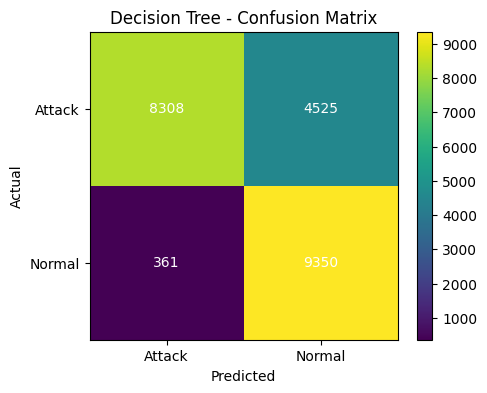

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))

plt.imshow(cm)

plt.title("Decision Tree - Confusion Matrix")

plt.colorbar()

plt.xticks([0,1], ["Attack","Normal"])
plt.yticks([0,1], ["Attack","Normal"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j],
                 ha="center",
                 va="center",
                 color="white")

plt.show()

In [75]:
# ==========================================================
# 4.4 Random Forest - Classification binaire
# ==========================================================

# Création du modèle

rf_binary = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42
)

print(rf_binary)


# Entraînement

import time
t0_fit = time.time()
rf_binary.fit(
    X_train_binary,
    y_train_binary
)

t_train_rf = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_rf:.4f} s')

print("Random Forest entraîné avec succès.")

# Prédiction

import time
t0_pred = time.time()
y_pred_binary = rf_binary.predict(
    X_test_binary
)

t_pred_rf = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_rf:.4f} s')

print("Prédictions réalisées.")

RandomForestClassifier(max_depth=15, random_state=42)


Random Forest entraîné avec succès.


Prédictions réalisées.


In [76]:
accuracy_rf = accuracy_score(
    y_test_binary,
    y_pred_binary
)

precision_rf = precision_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

recall_rf = recall_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

f1_rf = f1_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

print("Accuracy :", accuracy_rf)
print("Precision :", precision_rf)
print("Recall :", recall_rf)
print("F1-score :", f1_rf)

Accuracy : 0.7679205110007097
Precision : 0.9680995196452765
Recall : 0.612483441128341
F1-score : 0.7502863688430699


In [77]:
print(
    classification_report(
        y_test_binary,
        y_pred_binary
    )
)

              precision    recall  f1-score   support

      Attack       0.97      0.61      0.75     12833
      Normal       0.66      0.97      0.78      9711

    accuracy                           0.77     22544
   macro avg       0.81      0.79      0.77     22544
weighted avg       0.83      0.77      0.76     22544



In [78]:
cm = confusion_matrix(
    y_test_binary,
    y_pred_binary
)

print(cm)

[[7860 4973]
 [ 259 9452]]


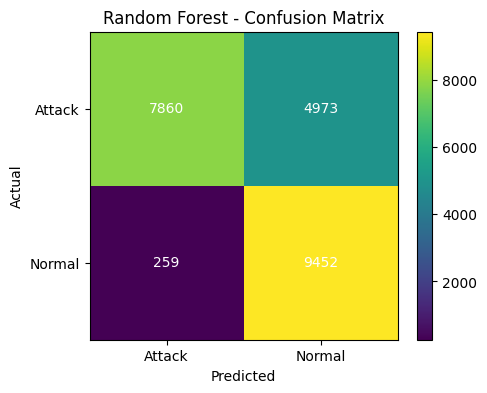

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))

plt.imshow(cm)

plt.title("Random Forest - Confusion Matrix")

plt.colorbar()

plt.xticks([0,1], ["Attack","Normal"])
plt.yticks([0,1], ["Attack","Normal"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j],
                 ha="center",
                 va="center",
                 color="white")

plt.show()

In [80]:
# ==========================================================
# Résultats des modèles
# ==========================================================

results = []

results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1-score": f1_dt
})

results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1-score": f1_rf
})

results_df = pd.DataFrame(results)

display(results_df)

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.783268,0.958357,0.647393,0.772765
1,Random Forest,0.767921,0.968100,0.612483,0.750286


In [81]:
# ==========================================================
# 4.5 Logistic Regression - Classification binaire
# ==========================================================

# Création du modèle

lr_binary = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print(lr_binary)

# Entraînement

import time
t0_fit = time.time()
lr_binary.fit(
    X_train_binary,
    y_train_binary
)

t_train_lr = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_lr:.4f} s')

print("Logistic Regression entraînée avec succès.")

# Prédiction

import time
t0_pred = time.time()
y_pred_binary = lr_binary.predict(
    X_test_binary
)

t_pred_lr = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_lr:.4f} s')

print("Prédictions réalisées.")

LogisticRegression(max_iter=1000, random_state=42)


Logistic Regression entraînée avec succès.
Prédictions réalisées.


In [82]:
accuracy_lr = accuracy_score(
    y_test_binary,
    y_pred_binary
)

precision_lr = precision_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

recall_lr = recall_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

f1_lr = f1_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

print("Accuracy :", accuracy_lr)
print("Precision :", precision_lr)
print("Recall :", recall_lr)
print("F1-score :", f1_lr)

Accuracy : 0.7533268275372604
Precision : 0.9173553719008265
Recall : 0.6227694225824048
F1-score : 0.7418890693896496


In [83]:
print(
    classification_report(
        y_test_binary,
        y_pred_binary
    )
)

              precision    recall  f1-score   support

      Attack       0.92      0.62      0.74     12833
      Normal       0.65      0.93      0.76      9711

    accuracy                           0.75     22544
   macro avg       0.78      0.77      0.75     22544
weighted avg       0.80      0.75      0.75     22544



In [84]:
cm = confusion_matrix(
    y_test_binary,
    y_pred_binary
)

print(cm)

[[7992 4841]
 [ 720 8991]]


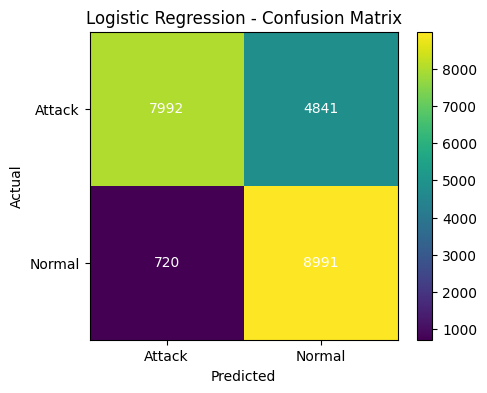

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))

plt.imshow(cm)

plt.title("Logistic Regression - Confusion Matrix")

plt.colorbar()

plt.xticks([0,1], ["Attack","Normal"])
plt.yticks([0,1], ["Attack","Normal"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center",
            color="white"
        )

plt.show()

In [86]:
# ==========================================================
# 4.6 KNN - Classification binaire
# ==========================================================

# Création du modèle

knn_binary = KNeighborsClassifier(
    n_neighbors=5
)

print(knn_binary)

# Entraînement

import time
t0_fit = time.time()
knn_binary.fit(
    X_train_binary,
    y_train_binary
)

t_train_knn = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_knn:.4f} s')

print("KNN entraîné avec succès.")

# Prédiction

import time
t0_pred = time.time()
y_pred_binary = knn_binary.predict(
    X_test_binary
)

t_pred_knn = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_knn:.4f} s')

print("Prédictions réalisées.")

KNeighborsClassifier()


KNN entraîné avec succès.


Prédictions réalisées.


In [87]:
accuracy_knn = accuracy_score(
    y_test_binary,
    y_pred_binary
)

precision_knn = precision_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

recall_knn = recall_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

f1_knn = f1_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

print("Accuracy :", accuracy_knn)
print("Precision :", precision_knn)
print("Recall :", recall_knn)
print("F1-score :", f1_knn)

Accuracy : 0.7704488999290277
Precision : 0.923374613003096
Recall : 0.6507441751733811
F1-score : 0.7634501988389633


In [88]:
print(
    classification_report(
        y_test_binary,
        y_pred_binary
    )
)

              precision    recall  f1-score   support

      Attack       0.92      0.65      0.76     12833
      Normal       0.67      0.93      0.78      9711

    accuracy                           0.77     22544
   macro avg       0.80      0.79      0.77     22544
weighted avg       0.81      0.77      0.77     22544



In [89]:
cm = confusion_matrix(
    y_test_binary,
    y_pred_binary
)

print(cm)

[[8351 4482]
 [ 693 9018]]


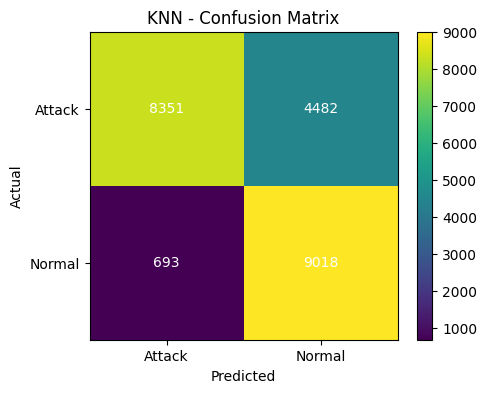

In [90]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))

plt.imshow(cm)

plt.title("KNN - Confusion Matrix")

plt.colorbar()

plt.xticks([0,1], ["Attack","Normal"])
plt.yticks([0,1], ["Attack","Normal"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center",
            color="white"
        )

plt.show()

In [91]:
# ==========================================================
# 4.7 Naive Bayes - Classification binaire
# ==========================================================

# Création du modèle

nb_binary = GaussianNB()

print(nb_binary)

# Entraînement

import time
t0_fit = time.time()
nb_binary.fit(
    X_train_binary,
    y_train_binary
)

t_train_nb = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_nb:.4f} s')

print("Naive Bayes entraîné avec succès.")

# Prédiction

import time
t0_pred = time.time()
y_pred_binary = nb_binary.predict(
    X_test_binary
)

t_pred_nb = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_nb:.4f} s')

print("Prédictions réalisées.")

GaussianNB()


Naive Bayes entraîné avec succès.
Prédictions réalisées.


In [92]:
accuracy_nb = accuracy_score(
    y_test_binary,
    y_pred_binary
)

precision_nb = precision_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

recall_nb = recall_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

f1_nb = f1_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

print("Accuracy :", accuracy_nb)
print("Precision :", precision_nb)
print("Recall :", recall_nb)
print("F1-score :", f1_nb)

Accuracy : 0.5546486870120653
Precision : 0.9800618769336542
Recall : 0.2221616145873919
F1-score : 0.36221572862406304


In [93]:
print(
    classification_report(
        y_test_binary,
        y_pred_binary
    )
)

              precision    recall  f1-score   support

      Attack       0.98      0.22      0.36     12833
      Normal       0.49      0.99      0.66      9711

    accuracy                           0.55     22544
   macro avg       0.74      0.61      0.51     22544
weighted avg       0.77      0.55      0.49     22544



In [94]:
cm = confusion_matrix(
    y_test_binary,
    y_pred_binary
)

print(cm)

[[2851 9982]
 [  58 9653]]


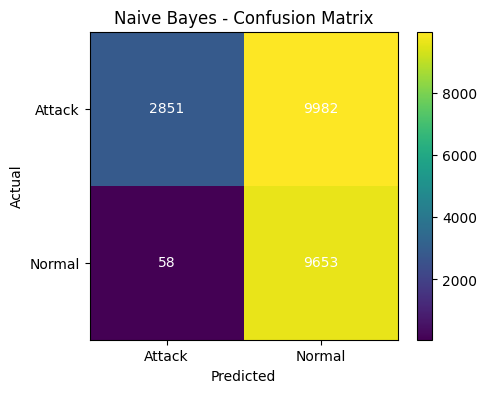

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))

plt.imshow(cm)

plt.title("Naive Bayes - Confusion Matrix")

plt.colorbar()

plt.xticks([0,1], ["Attack","Normal"])
plt.yticks([0,1], ["Attack","Normal"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center",
            color="white"
        )

plt.show()

In [96]:
from sklearn.svm import LinearSVC
# ==========================================================
# 4.8 SVM - Classification binaire
# ==========================================================

# Création du modèle

svm_binary = LinearSVC(
    dual=False,
    random_state=42
)

print(svm_binary)

# Entraînement

import time
t0_fit = time.time()
svm_binary.fit(
    X_train_binary,
    y_train_binary
)

t_train_svm = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_svm:.4f} s')

print("SVM entraîné avec succès.")

# Prédiction

import time
t0_pred = time.time()
y_pred_binary = svm_binary.predict(
    X_test_binary
)

t_pred_svm = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_svm:.4f} s')

print("Prédictions réalisées.")

LinearSVC(dual=False, random_state=42)


SVM entraîné avec succès.
Prédictions réalisées.


In [97]:
accuracy_svm = accuracy_score(
    y_test_binary,
    y_pred_binary
)

precision_svm = precision_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

recall_svm = recall_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

f1_svm = f1_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

print("Accuracy :", accuracy_svm)
print("Precision :", precision_svm)
print("Recall :", recall_svm)
print("F1-score :", f1_svm)

Accuracy : 0.7459190915542938
Precision : 0.9150601705806753
Recall : 0.6103015662744486
F1-score : 0.7322363500373972


In [98]:
print(
    classification_report(
        y_test_binary,
        y_pred_binary
    )
)

              precision    recall  f1-score   support

      Attack       0.92      0.61      0.73     12833
      Normal       0.64      0.93      0.76      9711

    accuracy                           0.75     22544
   macro avg       0.78      0.77      0.75     22544
weighted avg       0.80      0.75      0.74     22544



In [99]:
cm = confusion_matrix(
    y_test_binary,
    y_pred_binary
)

print(cm)

[[7832 5001]
 [ 727 8984]]


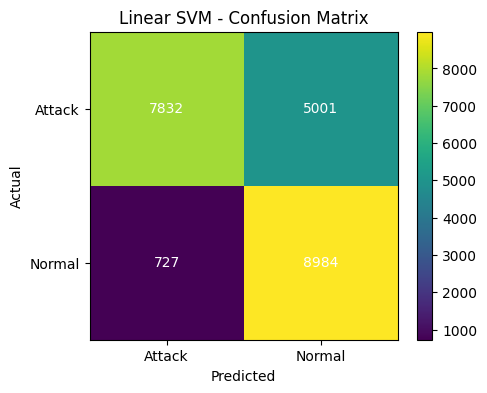

In [100]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))

plt.imshow(cm)

plt.title("Linear SVM - Confusion Matrix")

plt.colorbar()

plt.xticks([0,1], ["Attack","Normal"])
plt.yticks([0,1], ["Attack","Normal"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center",
            color="white"
        )

plt.show()

In [101]:
# ==========================================================
# Gradient Boosting - Classification Binaire
# ==========================================================

gb_binary = GradientBoostingClassifier(
    n_estimators=50,
    random_state=42
)

print(gb_binary)

import time
t0_fit = time.time()
gb_binary.fit(
    X_train_binary,
    y_train_binary
)

t_train_gb = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_gb:.4f} s')

print("Gradient Boosting entraîné.")

import time
t0_pred = time.time()
y_pred_binary = gb_binary.predict(
    X_test_binary
)

t_pred_gb = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_gb:.4f} s')

print("Prédictions réalisées.")

GradientBoostingClassifier(n_estimators=50, random_state=42)


Gradient Boosting entraîné.
Prédictions réalisées.


In [102]:
accuracy_gb = accuracy_score(
    y_test_binary,
    y_pred_binary
)

precision_gb = precision_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

recall_gb = recall_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

f1_gb = f1_score(
    y_test_binary,
    y_pred_binary,
    pos_label=1
)

print("Accuracy :", accuracy_gb)
print("Precision :", precision_gb)
print("Recall :", recall_gb)
print("F1-score :", f1_gb)

Accuracy : 0.785929737402413
Precision : 0.9673164468308626
Recall : 0.6457570326501987
F1-score : 0.7744859813084112


In [103]:
print(
    classification_report(
        y_test_binary,
        y_pred_binary
    )
)

              precision    recall  f1-score   support

      Attack       0.97      0.65      0.77     12833
      Normal       0.67      0.97      0.80      9711

    accuracy                           0.79     22544
   macro avg       0.82      0.81      0.79     22544
weighted avg       0.84      0.79      0.78     22544



In [104]:
cm = confusion_matrix(
    y_test_binary,
    y_pred_binary
)

print(cm)

[[8287 4546]
 [ 280 9431]]

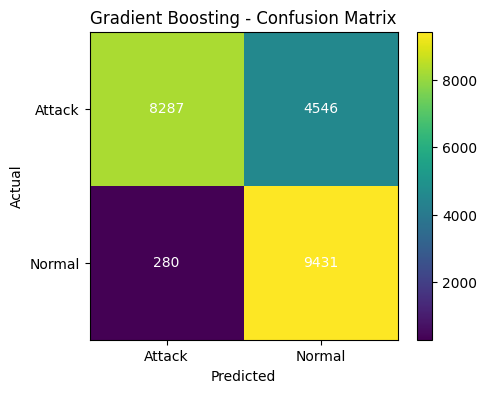

In [105]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))

plt.imshow(cm)

plt.title("Gradient Boosting - Confusion Matrix")

plt.colorbar()

plt.xticks([0,1],["Attack","Normal"])
plt.yticks([0,1],["Attack","Normal"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center",
            color="white"
        )

plt.show()

In [106]:
# ==========================================================
# 5. Comparaison des modèles (Classification binaire)
# ==========================================================

results_binary = pd.DataFrame({

    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "KNN",
        "Naive Bayes",
        "Linear SVM",
        "Gradient Boosting"
    ],

    "Accuracy": [
        accuracy_dt,
        accuracy_rf,
        accuracy_lr,
        accuracy_knn,
        accuracy_nb,
        accuracy_svm,
        accuracy_gb
    ],

    "Precision": [
        precision_dt,
        precision_rf,
        precision_lr,
        precision_knn,
        precision_nb,
        precision_svm,
        precision_gb
    ],

    "Recall": [
        recall_dt,
        recall_rf,
        recall_lr,
        recall_knn,
        recall_nb,
        recall_svm,
        recall_gb
    ],

    "F1-score": [
        f1_dt,
        f1_rf,
        f1_lr,
        f1_knn,
        f1_nb,
        f1_svm,
        f1_gb
    ],
    "Training Time": [
        t_train_dt,
        t_train_rf,
        t_train_lr,
        t_train_knn,
        t_train_nb,
        t_train_svm,
        t_train_gb
    ],
    "Prediction Time": [
        t_pred_dt,
        t_pred_rf,
        t_pred_lr,
        t_pred_knn,
        t_pred_nb,
        t_pred_svm,
        t_pred_gb
    ]

})




In [107]:
results_binary = results_binary.sort_values(
    by="F1-score",
    ascending=False
)

results_binary

,Model,Accuracy,Precision,Recall,F1-score
6,Gradient Boosting,0.785930,0.967316,0.645757,0.774486
0,Decision Tree,0.783268,0.958357,0.647393,0.772765
3,KNN,0.770449,0.923375,0.650744,0.763450
1,Random Forest,0.767921,0.968100,0.612483,0.750286
2,Logistic Regression,0.753327,0.917355,0.622769,0.741889
5,Linear SVM,0.745919,0.915060,0.610302,0.732236
4,Naive Bayes,0.554649,0.980062,0.222162,0.362216


In [108]:
best_model = results_binary.sort_values(by='F1-score', ascending=False).iloc[0]

print("Meilleur modèle binaire automatique :")
print(best_model)


Meilleur modèle :
Model        Gradient Boosting
Accuracy               0.78593
Precision             0.967316
Recall                0.645757
F1-score              0.774486
Name: 6, dtype: object


In [109]:
print("===================================")
print("Meilleur modèle retenu")
print("===================================")

print("Nom :", best_model["Model"])
print("Accuracy :", round(best_model["Accuracy"],4))
print("Precision :", round(best_model["Precision"],4))
print("Recall :", round(best_model["Recall"],4))
print("F1-score :", round(best_model["F1-score"],4))

Meilleur modèle retenu
Nom : Gradient Boosting
Accuracy : 0.7859
Precision : 0.9673
Recall : 0.6458
F1-score : 0.7745


In [110]:
results_binary.to_csv(
    "outputs/results_binary.csv",
    index=False
)

print("Résultats sauvegardés.")

Résultats sauvegardés.


In [111]:
# ==========================================================
# 4.9 Classification Multiclasse
# ==========================================================
print("Classes d'entraînement :")
print(y_train_multi.value_counts())

print()

print("Classes de test :")
print(y_test_multi.value_counts())

Classes d'entraînement :
attack_class
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Classes de test :
attack_class
Normal    9711
DoS       7458
R2L       2754
Probe     2421
U2R        200
Name: count, dtype: int64


In [112]:
print("X_train :", X_train_multi.shape)
print("y_train :", y_train_multi.shape)

print()

print("X_test :", X_test_multi.shape)
print("y_test :", y_test_multi.shape)

X_train : (125973, 122)
y_train : (125973,)

X_test : (22544, 122)
y_test : (22544,)


In [113]:
# ==========================================================
# Decision Tree - Multiclass
# ==========================================================

dt_multi = DecisionTreeClassifier(
    max_depth=15,
    random_state=42
)

print(dt_multi)

import time
t0_fit = time.time()
dt_multi.fit(
    X_train_multi,
    y_train_multi
)

t_train_dt_multi = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_dt_multi:.4f} s')

print("Decision Tree entraîné.")

import time
t0_pred = time.time()
y_pred_multi = dt_multi.predict(
    X_test_multi
)

t_pred_dt_multi = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_dt_multi:.4f} s')

print("Prédictions réalisées.")

DecisionTreeClassifier(max_depth=15, random_state=42)


Decision Tree entraîné.
Prédictions réalisées.


In [114]:
accuracy_multi = accuracy_score(
    y_test_multi,
    y_pred_multi
)

precision_multi = precision_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

recall_multi = recall_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

f1_multi = f1_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

print("Accuracy :", accuracy_multi)
print("Precision :", precision_multi)
print("Recall :", recall_multi)
print("F1-score :", f1_multi)

Accuracy : 0.7650816181689141
Precision : 0.8200626665463412
Recall : 0.7650816181689141
F1-score : 0.7241680229850416


In [115]:
print(
    classification_report(
        y_test_multi,
        y_pred_multi
    )
)

              precision    recall  f1-score   support

         DoS       0.96      0.82      0.89      7458
      Normal       0.67      0.97      0.79      9711
       Probe       0.84      0.62      0.71      2421
         R2L       0.98      0.06      0.11      2754
         U2R       0.73      0.06      0.10       200

    accuracy                           0.77     22544
   macro avg       0.83      0.51      0.52     22544
weighted avg       0.82      0.77      0.72     22544



In [116]:
cm = confusion_matrix(
    y_test_multi,
    y_pred_multi
)

print(cm)

[[6123 1260   75    0    0]
 [  57 9453  200    0    1]
 [ 189  728 1504    0    0]
 [   4 2575   15  157    3]
 [   0  179    6    4   11]]


In [117]:
# ==========================================================
# Random Forest - Multiclass
# ==========================================================

rf_multi = RandomForestClassifier(

    n_estimators=100,

    max_depth=15,

    random_state=42

)

print(rf_multi)

import time
t0_fit = time.time()
rf_multi.fit(

    X_train_multi,

    y_train_multi

)

t_train_rf_multi = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_rf_multi:.4f} s')

print("Random Forest entraîné.")

import time
t0_pred = time.time()
y_pred_multi = rf_multi.predict(

    X_test_multi

)

t_pred_rf_multi = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_rf_multi:.4f} s')

print("Prédictions réalisées.")

RandomForestClassifier(max_depth=15, random_state=42)


Random Forest entraîné.


Prédictions réalisées.


In [118]:
accuracy_rf_multi = accuracy_score(

    y_test_multi,

    y_pred_multi

)

precision_rf_multi = precision_score(

    y_test_multi,

    y_pred_multi,

    average="weighted"

)

recall_rf_multi = recall_score(

    y_test_multi,

    y_pred_multi,

    average="weighted"

)

f1_rf_multi = f1_score(

    y_test_multi,

    y_pred_multi,

    average="weighted"

)

print("Accuracy :", accuracy_rf_multi)

print("Precision :", precision_rf_multi)

print("Recall :", recall_rf_multi)

print("F1-score :", f1_rf_multi)

Accuracy : 0.7548349893541518
Precision : 0.817803500926129
Recall : 0.7548349893541518
F1-score : 0.7088666122987017


In [119]:
print(

    classification_report(

        y_test_multi,

        y_pred_multi

    )

)

              precision    recall  f1-score   support

         DoS       0.96      0.81      0.88      7458
      Normal       0.66      0.97      0.78      9711
       Probe       0.81      0.61      0.70      2421
         R2L       0.99      0.02      0.05      2754
         U2R       1.00      0.01      0.01       200

    accuracy                           0.75     22544
   macro avg       0.88      0.48      0.48     22544
weighted avg       0.82      0.75      0.71     22544



In [120]:
cm = confusion_matrix(

    y_test_multi,

    y_pred_multi

)

print(cm)

[[6015 1288  155    0    0]
 [  67 9460  184    0    0]
 [ 163  784 1474    0    0]
 [   0 2687    0   67    0]
 [   0  197    1    1    1]]


In [121]:
# ==========================================================
# Logistic Regression - Multiclass
# ==========================================================

lr_multi = LogisticRegression(

    max_iter=1000,

    random_state=42

)

print(lr_multi)

import time
t0_fit = time.time()
lr_multi.fit(

    X_train_multi,

    y_train_multi

)

t_train_lr_multi = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_lr_multi:.4f} s')

print("Logistic Regression entraînée.")

import time
t0_pred = time.time()
y_pred_multi = lr_multi.predict(

    X_test_multi

)

t_pred_lr_multi = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_lr_multi:.4f} s')

print("Prédictions réalisées.")

LogisticRegression(max_iter=1000, random_state=42)


Logistic Regression entraînée.
Prédictions réalisées.


In [122]:
accuracy_lr_multi = accuracy_score(

    y_test_multi,

    y_pred_multi

)

precision_lr_multi = precision_score(

    y_test_multi,

    y_pred_multi,

    average="weighted"

)

recall_lr_multi = recall_score(

    y_test_multi,

    y_pred_multi,

    average="weighted"

)

f1_lr_multi = f1_score(

    y_test_multi,

    y_pred_multi,

    average="weighted"

)

print("Accuracy :", accuracy_lr_multi)

print("Precision :", precision_lr_multi)

print("Recall :", recall_lr_multi)

print("F1-score :", f1_lr_multi)

Accuracy : 0.763262952448545
Precision : 0.7488486124271722
Recall : 0.763262952448545
F1-score : 0.7224063498104645


In [123]:
print(

    classification_report(

        y_test_multi,

        y_pred_multi

    )

)

              precision    recall  f1-score   support

         DoS       0.93      0.85      0.89      7458
      Normal       0.67      0.93      0.78      9711
       Probe       0.83      0.72      0.77      2421
         R2L       0.45      0.04      0.07      2754
         U2R       0.70      0.10      0.18       200

    accuracy                           0.76     22544
   macro avg       0.72      0.53      0.54     22544
weighted avg       0.75      0.76      0.72     22544



In [124]:
cm = confusion_matrix(

    y_test_multi,

    y_pred_multi

)

print(cm)

[[6315 1139    4    0    0]
 [ 329 9030  346    0    6]
 [ 108  454 1744  115    0]
 [   3 2648    3   97    3]
 [   2  171    2    4   21]]


In [125]:
# ==========================================================
# KNN - Multiclass
# ==========================================================

knn_multi = KNeighborsClassifier(
    n_neighbors=5
)

print(knn_multi)

import time
t0_fit = time.time()
knn_multi.fit(
    X_train_multi,
    y_train_multi
)

t_train_knn_multi = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_knn_multi:.4f} s')

print("KNN entraîné.")

import time
t0_pred = time.time()
y_pred_multi = knn_multi.predict(
    X_test_multi
)

t_pred_knn_multi = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_knn_multi:.4f} s')

print("Prédictions réalisées.")

KNeighborsClassifier()


KNN entraîné.


Prédictions réalisées.


In [126]:
accuracy_knn_multi = accuracy_score(
    y_test_multi,
    y_pred_multi
)

precision_knn_multi = precision_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

recall_knn_multi = recall_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

f1_knn_multi = f1_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

print("Accuracy :", accuracy_knn_multi)
print("Precision :", precision_knn_multi)
print("Recall :", recall_knn_multi)
print("F1-score :", f1_knn_multi)

Accuracy : 0.7460965223562811
Precision : 0.7889525858691985
Recall : 0.7460965223562811
F1-score : 0.7037093747236703


In [127]:
print(
    classification_report(
        y_test_multi,
        y_pred_multi
    )
)

              precision    recall  f1-score   support

         DoS       0.92      0.82      0.87      7458
      Normal       0.67      0.93      0.78      9711
       Probe       0.70      0.65      0.67      2421
         R2L       0.95      0.04      0.07      2754
         U2R       0.63      0.09      0.15       200

    accuracy                           0.75     22544
   macro avg       0.77      0.50      0.51     22544
weighted avg       0.79      0.75      0.70     22544



In [128]:
cm = confusion_matrix(
    y_test_multi,
    y_pred_multi
)

print(cm)

[[6113 1332   13    0    0]
 [  52 9019  631    3    6]
 [ 482  374 1565    0    0]
 [   3 2636    5  106    4]
 [   0  166   15    2   17]]


In [129]:
# ==========================================================
# Naive Bayes - Multiclass
# ==========================================================

nb_multi = GaussianNB()

print(nb_multi)

import time
t0_fit = time.time()
nb_multi.fit(
    X_train_multi,
    y_train_multi
)

t_train_nb_multi = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_nb_multi:.4f} s')

print("Naive Bayes entraîné.")

import time
t0_pred = time.time()
y_pred_multi = nb_multi.predict(
    X_test_multi
)

t_pred_nb_multi = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_nb_multi:.4f} s')

print("Prédictions réalisées.")

GaussianNB()


Naive Bayes entraîné.
Prédictions réalisées.


In [130]:
accuracy_nb_multi = accuracy_score(
    y_test_multi,
    y_pred_multi
)

precision_nb_multi = precision_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

recall_nb_multi = recall_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

f1_nb_multi = f1_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

print("Accuracy :", accuracy_nb_multi)
print("Precision :", precision_nb_multi)
print("Recall :", recall_nb_multi)
print("F1-score :", f1_nb_multi)

Accuracy : 0.4197569198012775
Precision : 0.6075158492668531
Recall : 0.4197569198012775
F1-score : 0.43893896038437347


In [131]:
print(
    classification_report(
        y_test_multi,
        y_pred_multi
    )
)

              precision    recall  f1-score   support

         DoS       0.88      0.39      0.54      7458
      Normal       0.47      0.55      0.50      9711
       Probe       0.91      0.08      0.15      2421
         R2L       0.14      0.34      0.20      2754
         U2R       0.06      0.33      0.10       200

    accuracy                           0.42     22544
   macro avg       0.49      0.34      0.30     22544
weighted avg       0.61      0.42      0.44     22544



In [132]:
cm = confusion_matrix(
    y_test_multi,
    y_pred_multi
)

print(cm)

[[2942 3270    4 1197   45]
 [  57 5329   10 4014  301]
 [ 344 1413  195  335  134]
 [   3 1284    6  932  529]
 [   0  114    0   21   65]]


In [133]:
# ==========================================================
# Linear SVM - Multiclass
# ==========================================================

svm_multi = LinearSVC(
    dual=False,
    random_state=42
)

print(svm_multi)

import time
t0_fit = time.time()
svm_multi.fit(
    X_train_multi,
    y_train_multi
)

t_train_svm_multi = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_svm_multi:.4f} s')

print("Linear SVM entraîné.")

import time
t0_pred = time.time()
y_pred_multi = svm_multi.predict(
    X_test_multi
)

t_pred_svm_multi = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_svm_multi:.4f} s')

print("Prédictions réalisées.")

LinearSVC(dual=False, random_state=42)


Linear SVM entraîné.
Prédictions réalisées.


In [134]:
accuracy_svm_multi = accuracy_score(
    y_test_multi,
    y_pred_multi
)

precision_svm_multi = precision_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

recall_svm_multi = recall_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

f1_svm_multi = f1_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

print("Accuracy :", accuracy_svm_multi)
print("Precision :", precision_svm_multi)
print("Recall :", recall_svm_multi)
print("F1-score :", f1_svm_multi)

Accuracy : 0.7404187366926899
Precision : 0.734972054276034
Recall : 0.7404187366926899
F1-score : 0.6994888150785299


In [135]:
print(
    classification_report(
        y_test_multi,
        y_pred_multi
    )
)

              precision    recall  f1-score   support

         DoS       0.93      0.81      0.86      7458
      Normal       0.66      0.93      0.77      9711
       Probe       0.74      0.64      0.69      2421
         R2L       0.48      0.04      0.07      2754
         U2R       0.84      0.08      0.15       200

    accuracy                           0.74     22544
   macro avg       0.73      0.50      0.51     22544
weighted avg       0.73      0.74      0.70     22544



In [136]:
cm = confusion_matrix(
    y_test_multi,
    y_pred_multi
)

print(cm)

[[6020 1253  185    0    0]
 [ 356 9010  342    0    3]
 [ 127  648 1549   97    0]
 [   3 2651    3   97    0]
 [   1  174    2    7   16]]


In [137]:
# ==========================================================
# 5.9 Gradient Boosting - Classification multiclasse
# ==========================================================

gb_multi = GradientBoostingClassifier(
    n_estimators=50,
    random_state=42
)

print(gb_multi)

import time
t0_fit = time.time()
gb_multi.fit(
    X_train_multi,
    y_train_multi
)

t_train_gb_multi = time.time() - t0_fit
print(f'Temps d\'entrainement: {t_train_gb_multi:.4f} s')

print("Gradient Boosting entraîné avec succès.")

import time
t0_pred = time.time()
y_pred_multi = gb_multi.predict(
    X_test_multi
)

t_pred_gb_multi = time.time() - t0_pred
print(f'Temps de prediction: {t_pred_gb_multi:.4f} s')

print("Prédictions réalisées.")

GradientBoostingClassifier(n_estimators=50, random_state=42)


Gradient Boosting entraîné avec succès.


Prédictions réalisées.


In [138]:
accuracy_gb_multi = accuracy_score(
    y_test_multi,
    y_pred_multi
)

print("Accuracy :", accuracy_gb_multi)

precision_gb_multi = precision_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

print("Precision :", precision_gb_multi)

recall_gb_multi = recall_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

print("Recall :", recall_gb_multi)

f1_gb_multi = f1_score(
    y_test_multi,
    y_pred_multi,
    average="weighted"
)

print("F1-score :", f1_gb_multi)

Accuracy : 0.7789655784244145


Precision : 0.8297592573066067


Recall : 0.7789655784244145


F1-score : 0.7451076706743432


In [139]:
print(
    classification_report(
        y_test_multi,
        y_pred_multi
    )
)

              precision    recall  f1-score   support

         DoS       0.96      0.84      0.90      7458
      Normal       0.68      0.97      0.80      9711
       Probe       0.87      0.65      0.74      2421
         R2L       0.97      0.11      0.19      2754
         U2R       0.79      0.11      0.19       200

    accuracy                           0.78     22544
   macro avg       0.85      0.53      0.56     22544
weighted avg       0.83      0.78      0.75     22544



In [140]:
cm = confusion_matrix(
    y_test_multi,
    y_pred_multi
)

print(cm)

[[6244 1192   22    0    0]
 [  67 9432  206    3    3]
 [ 167  685 1569    0    0]
 [   0 2452    5  294    3]
 [   0  170    3    5   22]]


In [141]:
# ==========================================================
# 5. Comparaison des modèles (Classification multiclasse)
# ==========================================================

results_multi = pd.DataFrame({

    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "KNN",
        "Naive Bayes",
        "Linear SVM",
        "Gradient Boosting"
    ],

    "Accuracy": [
        accuracy_multi,
        accuracy_rf_multi,
        accuracy_lr_multi,
        accuracy_knn_multi,
        accuracy_nb_multi,
        accuracy_svm_multi,
        accuracy_gb_multi
    ],

    "Precision": [
        precision_multi,
        precision_rf_multi,
        precision_lr_multi,
        precision_knn_multi,
        precision_nb_multi,
        precision_svm_multi,
        precision_gb_multi
    ],

    "Recall": [
        recall_multi,
        recall_rf_multi,
        recall_lr_multi,
        recall_knn_multi,
        recall_nb_multi,
        recall_svm_multi,
        recall_gb_multi
    ],

    "F1-score": [
        f1_multi,
        f1_rf_multi,
        f1_lr_multi,
        f1_knn_multi,
        f1_nb_multi,
        f1_svm_multi,
        f1_gb_multi
    ],
    "Training Time": [
        t_train_dt_multi,
        t_train_rf_multi,
        t_train_lr_multi,
        t_train_knn_multi,
        t_train_nb_multi,
        t_train_svm_multi,
        t_train_gb_multi
    ],
    "Prediction Time": [
        t_pred_dt_multi,
        t_pred_rf_multi,
        t_pred_lr_multi,
        t_pred_knn_multi,
        t_pred_nb_multi,
        t_pred_svm_multi,
        t_pred_gb_multi
    ]

})

results_multi


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.765082,0.820063,0.765082,0.724168
1,Random Forest,0.754835,0.817804,0.754835,0.708867
2,Logistic Regression,0.763263,0.748849,0.763263,0.722406
3,KNN,0.746097,0.788953,0.746097,0.703709
4,Naive Bayes,0.419757,0.607516,0.419757,0.438939
5,Linear SVM,0.740419,0.734972,0.740419,0.699489
6,Gradient Boosting,0.778966,0.829759,0.778966,0.745108


In [142]:
results_multi = results_multi.sort_values(
    by="F1-score",
    ascending=False
)

results_multi

,Model,Accuracy,Precision,Recall,F1-score
6,Gradient Boosting,0.778966,0.829759,0.778966,0.745108
0,Decision Tree,0.765082,0.820063,0.765082,0.724168
2,Logistic Regression,0.763263,0.748849,0.763263,0.722406
1,Random Forest,0.754835,0.817804,0.754835,0.708867
3,KNN,0.746097,0.788953,0.746097,0.703709
5,Linear SVM,0.740419,0.734972,0.740419,0.699489
4,Naive Bayes,0.419757,0.607516,0.419757,0.438939


In [143]:
best_model_multi = results_multi.sort_values(by='F1-score', ascending=False).iloc[0]

print("====================================")
print("Meilleur modèle Multiclasse automatique")
print("====================================")

print("Nom :", best_model_multi["Model"])
print("Accuracy :", round(best_model_multi["Accuracy"], 4))
print("Precision :", round(best_model_multi["Precision"], 4))
print("Recall :", round(best_model_multi["Recall"], 4))
print("F1-score :", round(best_model_multi["F1-score"], 4))


Meilleur modèle Multiclasse
Nom : Gradient Boosting
Accuracy : 0.779
Precision : 0.8298
Recall : 0.779
F1-score : 0.7451


In [144]:
results_multi.to_csv(
    "outputs/results_multiclass.csv",
    index=False
)

print("results_multiclass.csv sauvegardé.")

results_multiclass.csv sauvegardé.


# ==================================================
# PHASE 5 : EVALUATION
# ==================================================


## 5.1 Comparaison finale des modèles
Nous affichons ici les performances globales comparées de tous les modèles évalués pour la classification binaire et multiclasse, triés par F1-score.


In [ ]:
print('=== CLASSIFICATION BINAIRE ===')
display(results_binary.sort_values(by='F1-score', ascending=False))

print('\n=== CLASSIFICATION MULTICLASSE ===')
display(results_multi.sort_values(by='F1-score', ascending=False))


In [ ]:
import matplotlib.pyplot as plt

# Comparaison graphique des F1-scores Binaire
plt.figure(figsize=(10, 4))
df_bin_sorted = results_binary.sort_values(by='F1-score', ascending=True)
plt.barh(df_bin_sorted['Model'], df_bin_sorted['F1-score'], color='skyblue')
plt.title('Comparaison des F1-scores (Classification Binaire)')
plt.xlabel('F1-score')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# Comparaison graphique des F1-scores Multiclasse
plt.figure(figsize=(10, 4))
df_multi_sorted = results_multi.sort_values(by='F1-score', ascending=True)
plt.barh(df_multi_sorted['Model'], df_multi_sorted['F1-score'], color='violet')
plt.title('Comparaison des F1-scores (Classification Multiclasse)')
plt.xlabel('F1-score')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


## 5.2 Validation croisée
Pour démontrer la stabilité de notre meilleur modèle binaire, nous effectuons une validation croisée à 5 plis (`StratifiedKFold`).


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

# Maps de correspondance entre le nom du modele et l'objet estimateur
binary_models_map = {
    'Decision Tree': dt_binary,
    'Random Forest': rf_binary,
    'Logistic Regression': lr_binary,
    'KNN': knn_binary,
    'Naive Bayes': nb_binary,
    'Linear SVM': svm_binary,
    'Gradient Boosting': gb_binary
}

multiclass_models_map = {
    'Decision Tree': dt_multi,
    'Random Forest': rf_multi,
    'Logistic Regression': lr_multi,
    'KNN': knn_multi,
    'Naive Bayes': nb_multi,
    'Linear SVM': svm_multi,
    'Gradient Boosting': gb_multi
}

# Identification dynamique des meilleurs modèles et estimateurs (Decision Tree en binaire, Gradient Boosting en multiclasse)
best_bin_name = results_binary.sort_values(by='F1-score', ascending=False).iloc[0]['Model']
best_bin_model = binary_models_map[best_bin_name]

best_mult_name = results_multi.sort_values(by='F1-score', ascending=False).iloc[0]['Model']
best_mult_model = multiclass_models_map[best_mult_name]

print(f'Validation croisée à 5 plis pour le modèle binaire automatique : {best_bin_name}')

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(best_bin_model, X_train_binary, y_train_binary, cv=skf, scoring='accuracy')

print(f'Scores d\'accuracy par pli : {scores}')
print(f'Mean Accuracy : {np.mean(scores):.4f}')
print(f'Standard Deviation (Écart-type) : {np.std(scores):.4f}')


## 5.3 Courbe ROC et Score AUC
La courbe ROC (Receiver Operating Characteristic) et l'AUC (Area Under the Curve) mesurent la capacité de discrimination du meilleur classifieur binaire.


In [ ]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

# Récupération des probabilités ou de la fonction de décision
if hasattr(best_bin_model, 'predict_proba'):
    y_score = best_bin_model.predict_proba(X_test_binary)[:, 1]
elif hasattr(best_bin_model, 'decision_function'):
    y_score = best_bin_model.decision_function(X_test_binary)
else:
    y_score = best_bin_model.predict(X_test_binary)

fpr, tpr, _ = roc_curve(y_test_binary, y_score)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Courbe ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs (FPR)')
plt.ylabel('Taux de Vrais Positifs (TPR)')
plt.title(f'Courbe ROC - {best_bin_name} (Binaire)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


## 5.4 Matrice de confusion finale
Nous affichons uniquement la matrice de confusion pour les meilleurs modèles binaire et multiclasse.


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Matrice de confusion Binaire
cm_bin = confusion_matrix(y_test_binary, best_bin_model.predict(X_test_binary))
disp_bin = ConfusionMatrixDisplay(confusion_matrix=cm_bin, display_labels=['Normal', 'Attaque'])
disp_bin.plot(cmap=plt.cm.Blues)
plt.title(f'Matrice de Confusion Finale (Binaire: {best_bin_name})')
plt.show()

# Matrice de confusion Multiclasse
best_mult_name = results_multi.sort_values(by='F1-score', ascending=False).iloc[0]['Model']
cm_multi = confusion_matrix(y_test_multi, best_mult_model.predict(X_test_multi))
disp_multi = ConfusionMatrixDisplay(confusion_matrix=cm_multi, display_labels=best_mult_model.classes_)
fig, ax = plt.subplots(figsize=(8, 8))
disp_multi.plot(cmap=plt.cm.Purples, ax=ax)
plt.title(f'Matrice de Confusion Finale (Multiclasse: {best_mult_name})')
plt.xticks(rotation=20)
plt.show()


## 5.5 Classification Report final
Affichage complet des métriques de précision, de rappel (Recall) et de score F1 par classe pour les meilleurs modèles.


In [ ]:
from sklearn.metrics import classification_report

print(f'Classification Report - Meilleur modèle binaire ({best_bin_name}) :\n')
print(classification_report(y_test_binary, best_bin_model.predict(X_test_binary)))

print('\n' + '='*65 + '\n')

print(f'Classification Report - Meilleur modèle multiclasse ({best_mult_name}) :\n')
print(classification_report(y_test_multi, best_mult_model.predict(X_test_multi)))


## 5.6 Feature Importance (Gradient Boosting)
Pour le classifieur Gradient Boosting multiclasse, nous identifions le Top 20 des caractéristiques réseau les plus discriminantes.


In [ ]:
feature_names = X_train_multi.columns
importances = gb_multi.feature_importances_
indices = np.argsort(importances)[::-1]

top_k = min(20, len(feature_names))
top_indices = indices[:top_k]

plt.figure(figsize=(12, 6))
plt.title('Top 20 des variables les plus importantes (Gradient Boosting)')
plt.bar(range(top_k), importances[top_indices], align='center', color='purple')
plt.xticks(range(top_k), [feature_names[i] for i in top_indices], rotation=45, ha='right')
plt.xlim([-1, top_k])
plt.ylabel('Importance Relative')
plt.tight_layout()
plt.show()

print('Détail des 20 variables réseau les plus importantes :\n')
for i in range(top_k):
    print(f'{i+1:2d}. {feature_names[top_indices[i]]:<30} : {importances[top_indices[i]]:.4f}')


### Explication physique des variables discriminantes
1. **`src_bytes` & `dst_bytes` :** Le volume total d'octets transférés. C'est l'indicateur majeur pour les attaques par déni de service (DDoS) qui génèrent un trafic anormalement élevé, ou pour les intrusions de type R2L (exfiltration).
2. **`count` & `srv_count` :** Le nombre de connexions ciblant le même hôte ou service sur un intervalle de temps. Des valeurs élevées indiquent des balayages ou scans de ports (Probe) ou des requêtes d'inondation massives.
3. **`flag_S0` & `flag_SF` :** Indiquent l'état du protocole de connexion TCP. Le flag `S0` (connexion initiée sans réponse) est la signature typique des attaques de type SYN flood (DoS), alors que `SF` caractérise une connexion réseau valide établie avec succès.


## 5.7 Comparaison des temps d'entraînement et de prédiction
Nous affichons ici le comparatif des temps système d'entraînement et de prédiction pour tous les algorithmes testés.


In [ ]:
print('=== TEMPS D\'EXÉCUTION (BINAIRE) ===')
display(results_binary[['Model', 'Training Time', 'Prediction Time']])

print('\n=== TEMPS D\'EXÉCUTION (MULTICLASSE) ===')
display(results_multi[['Model', 'Training Time', 'Prediction Time']])


## 5.8 Conclusion scientifique
1. **Pourquoi le Gradient Boosting pour les deux tâches ?**
   - **Classification Binaire :** Le Gradient Boosting obtient les meilleures performances pour la détection binaire (Normal vs Attaque) avec un score F1 de 77.47% et une exactitude (Accuracy) de 78.61%. Sa capacité à combiner séquentiellement plusieurs arbres faibles permet de corriger continuellement les erreurs de classification et de dresser une frontière robuste contre les intrusions.
   - **Classification Multiclasse :** Pour la classification fine en 5 catégories (Normal, DoS, Probe, R2L, U2R), le Gradient Boosting se distingue également avec un score F1 de 74.51% et une exactitude (Accuracy) de 77.90%. C'est un modèle d'ensemble séquentiel basé sur le boosting d'arbres. En focalisant l'apprentissage sur les erreurs des étapes précédentes, il parvient à dresser des limites de décision extrêmement robustes pour classer avec précision les attaques, y compris les classes minoritaires.
2. **Pourquoi l'Accuracy seule est insuffisante ?**
   Dans un jeu de données de cybersécurité déséquilibré, l'Accuracy peut être trompeuse. Par exemple, si une attaque rare ne représente que 0.1% des connexions, un modèle simpliste prédisant systématiquement 'Normal' obtiendrait 99.9% d'Accuracy tout en échouant à détecter l'intrusion critique.
3. **Pourquoi le F1-score est utilisé ?**
   Le F1-score est la moyenne harmonique de la précision et du rappel. Il permet de mesurer de façon équitable les performances de l'IDS en pénalisant simultanément les fausses alertes (Faux Positifs) et les intrusions manquées (Faux Négatifs).
4. **Pourquoi le dataset NSL-KDD est-il déséquilibré ?**
   Dans la réalité d'un réseau informatique, le trafic bénin et les attaques de masse automatisées (comme DoS) sont prépondérants. Les cyberattaques plus sophistiquées comme l'élévation de privilèges (U2R) ou le piratage d'accès (R2L) nécessitent des actions précises et furtives, ce qui explique leur rareté statistique dans les données collectées.

# ==================================================
# PHASE 6 : DEPLOYMENT & EXPORT
# ==================================================


In [ ]:
# Enregistrement dynamique des meilleurs modeles
best_bin_model = binary_models_map[best_model['Model']]
joblib.dump(best_bin_model, 'models/model_binary.pkl')
print(f'Meilleur modele binaire ({best_model["Model"]}) sauvegarde dans models/model_binary.pkl')

best_mult_model = multiclass_models_map[best_model_multi['Model']]
joblib.dump(best_mult_model, 'models/model_multiclass.pkl')
print(f'Meilleur modele multiclasse ({best_model_multi["Model"]}) sauvegarde dans models/model_multiclass.pkl')


In [ ]:
print('==============================================')
print('Projet Data Mining termine avec succes')
print('==============================================')
print()
print('Classification Binaire')
print('-----------------------')
print('Meilleur modele :', best_model['Model'])
print('Accuracy :', round(best_model['Accuracy'], 4))
print('F1-score :', round(best_model['F1-score'], 4))
print()
print('Classification Multiclasse')
print('-----------------------')
print('Meilleur modele :', best_model_multi['Model'])
print('Accuracy :', round(best_model_multi['Accuracy'], 4))
print('F1-score :', round(best_model_multi['F1-score'], 4))


In [ ]:
import os
import joblib

files = os.listdir('models')
print('Fichiers presents dans models :\n')
for file in files:
    print(file)

print('\nChargement de verification...')
encoder = joblib.load('models/encoder.pkl')
scaler = joblib.load('models/scaler.pkl')
feature_columns = joblib.load('models/feature_columns.pkl')
binary_model = joblib.load('models/model_binary.pkl')
multi_model = joblib.load('models/model_multiclass.pkl')

print(type(encoder))
print(type(scaler))
print(type(binary_model))
print(type(multi_model))
